In [1]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 953.6 kB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

In [9]:
INPUT_DIR = Path("/kaggle/input")
DATA_DIR = INPUT_DIR / "competitions" / "cats-and-dogs"
CLASSES = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]
MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_WEIGHTS = Path("/kaggle/input/datasets/illiav123/model-for-grad-cam/convnext_tiny.fb_in1k_384x448_rep5_fold0.pt")
FOLDS_CSV = Path("/kaggle/input/datasets/illiav123/folds-grad-cam/train_folds.csv")
print(MODEL_WEIGHTS, FOLDS_CSV, DEVICE, sep="\n")
print("checkpoint found:", MODEL_WEIGHTS.exists(), "| folds found:", FOLDS_CSV.exists(),
      "| competition data found:", (DATA_DIR / "train.csv").exists())

/kaggle/input/datasets/illiav123/model-for-grad-cam/convnext_tiny.fb_in1k_384x448_rep5_fold0.pt
/kaggle/input/datasets/illiav123/folds-grad-cam/train_folds.csv
cpu
checkpoint found: True | folds found: True | competition data found: True


In [11]:
MODEL_WEIGHTS = torch.load(MODEL_WEIGHTS, map_location="cpu", weights_only=False)
if "state_dict" in MODEL_WEIGHTS:              
    print("stored settings:", {k: v for k, v in MODEL_WEIGHTS.items() if k != "state_dict"})
    state = MODEL_WEIGHTS["state_dict"]
    H, W = MODEL_WEIGHTS.get("H", 384), MODEL_WEIGHTS.get("W", 448)
else:                                       
    state, H, W = MODEL_WEIGHTS, 384, 448

model_name = "convnext_tiny.fb_in1k"        
trained_model = timm.create_model(model_name, num_classes=len(CLASSES))
trained_model.load_state_dict({k.replace("model.", ""): v for k, v in state.items()})
trained_model.to(DEVICE)
trained_model.eval()
print(model_name, H, W)

convnext_tiny.fb_in1k 384 448


In [12]:
def load_image(image_id, folder="train"):
    """Resized RGB in [0, 1] for display + normalised tensor for the model."""
    img = cv2.cvtColor(cv2.imread(str(DATA_DIR / folder / f"{image_id}.jpg")), cv2.COLOR_BGR2RGB)
    rgb = np.float32(cv2.resize(img, (W, H))) / 255.0
    tensor = torch.from_numpy(((rgb - MEAN) / STD).transpose(2, 0, 1)).float()
    return rgb, tensor


df = pd.read_csv(FOLDS_CSV)
df = df[df["fold"] == 0]
rows = [df[df[c] == 1].sample(1, random_state=0).iloc[0] for c in CLASSES]
rgb_imgs, tensors = zip(*[load_image(r["image_id"]) for r in rows])
tensors = torch.stack(tensors).to(DEVICE)
labels = np.stack([r[CLASSES].values.astype(int) for r in rows])

with torch.no_grad():
    probs = torch.sigmoid(trained_model(tensors)).cpu().numpy()
preds = (probs > 0.5).astype(int)

In [13]:
target_layers = [trained_model.get_submodule("stages.3")]           
targets = [ClassifierOutputTarget(i) for i in range(len(CLASSES))]
with GradCAM(model=trained_model, target_layers=target_layers) as cam:
    grayscale_cams = cam(input_tensor=tensors, targets=targets)

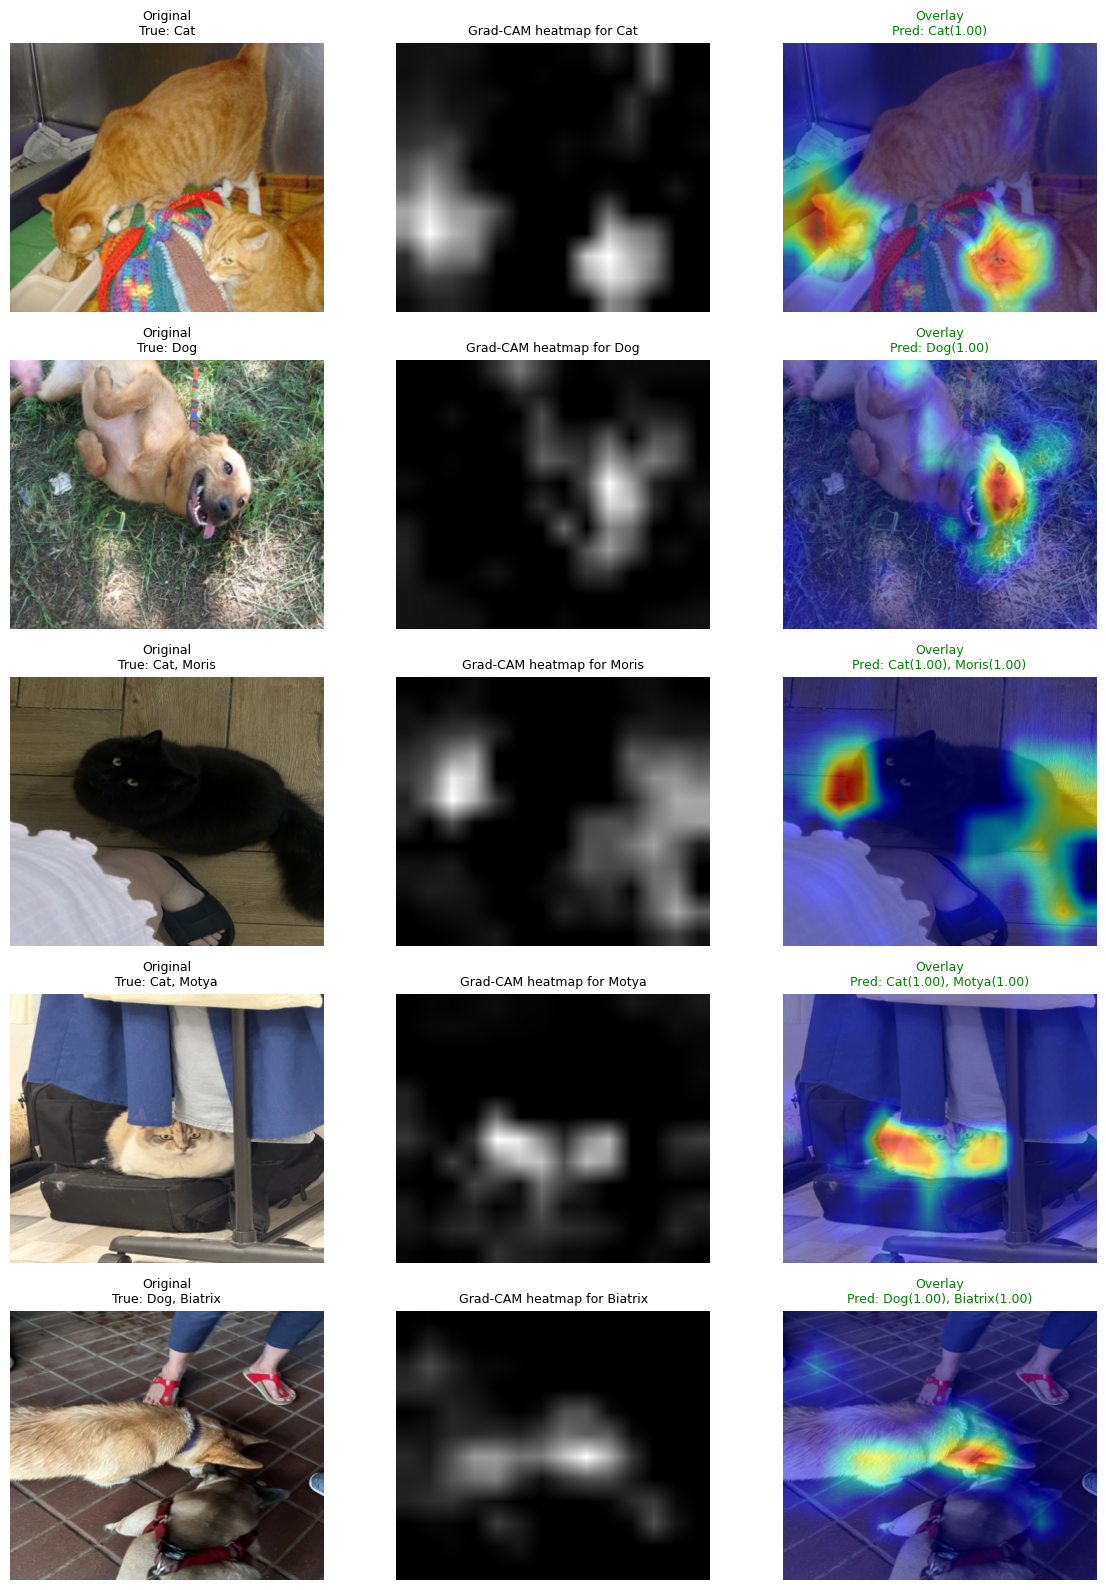

In [14]:
n = len(rows)
fig, axes = plt.subplots(n, 3, figsize=(12, 3.2 * n))
for i in range(n):
    cam_image = show_cam_on_image(rgb_imgs[i], grayscale_cams[i], use_rgb=True)
    true_cls = [CLASSES[j] for j in range(len(CLASSES)) if labels[i, j] == 1]
    pred_cls = [f"{CLASSES[j]}({probs[i, j]:.2f})" for j in range(len(CLASSES)) if preds[i, j] == 1]

    axes[i, 0].imshow(rgb_imgs[i])
    axes[i, 0].set_title(f"Original\nTrue: {', '.join(true_cls)}", fontsize=9)
    axes[i, 1].imshow(grayscale_cams[i], cmap="gray")
    axes[i, 1].set_title(f"Grad-CAM heatmap for {CLASSES[i]}", fontsize=9)
    axes[i, 2].imshow(cam_image)
    axes[i, 2].set_title(f"Overlay\nPred: {', '.join(pred_cls) or 'none'}", fontsize=9,
                         color="green" if (labels[i] == preds[i]).all() else "red")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

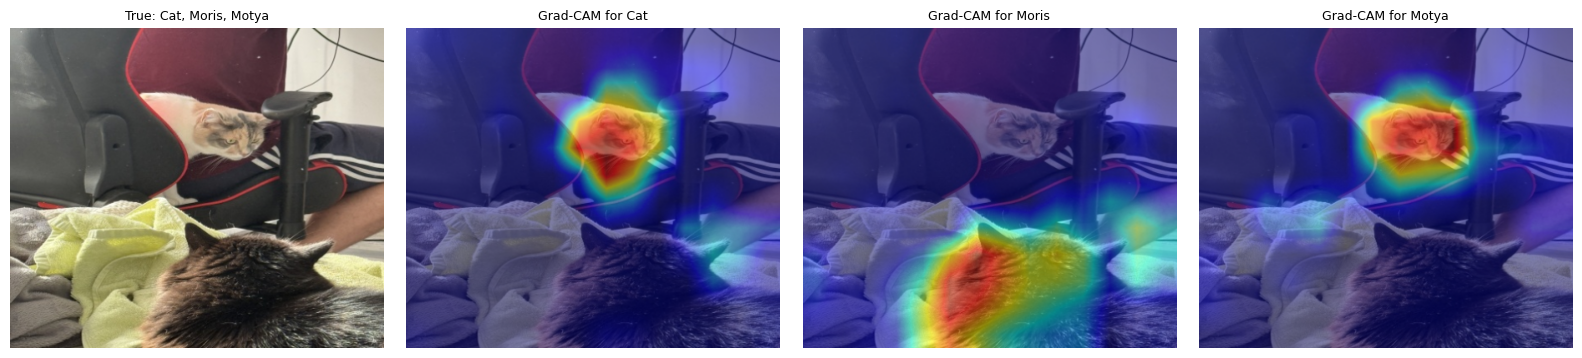

In [15]:
row = df[df[CLASSES].sum(axis=1) >= 2].sample(1, random_state=0).iloc[0]
present = [j for j, c in enumerate(CLASSES) if row[c] == 1]
rgb, tensor = load_image(row["image_id"])
batch = tensor[None].repeat(len(present), 1, 1, 1).to(DEVICE)    # same image once per class
with GradCAM(model=trained_model, target_layers=target_layers) as cam:
    maps = cam(input_tensor=batch, targets=[ClassifierOutputTarget(j) for j in present])

fig, axes = plt.subplots(1, len(present) + 1, figsize=(4 * (len(present) + 1), 3.5))
axes[0].imshow(rgb)
axes[0].set_title("True: " + ", ".join(CLASSES[j] for j in present), fontsize=9)
for ax, j, m in zip(axes[1:], present, maps):
    ax.imshow(show_cam_on_image(rgb, m, use_rgb=True))
    ax.set_title(f"Grad-CAM for {CLASSES[j]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()